# 02 · Modelos estadísticos sobre la serie diaria

Este notebook construye y diagnostica los modelos ARIMA, SARIMA y SARIMAX sobre la demanda diaria. Los parámetros se estiman con los días anteriores al 2012-12-02; los 30 días restantes son la prueba.

Cada modelo se usa en dos escenarios de pronóstico (el notebook 04 los compara con machine learning):

- **B. Día siguiente:** al cierre de cada día se pronostica el siguiente. El filtro de Kalman incorpora el día observado sin reestimar parámetros.
- **C. Mes completo:** el 1 de diciembre se pronostican de una vez los 30 días siguientes.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from bike_sharing import RANDOM_STATE, datos
from bike_sharing.datos import RAIZ, INICIO_PRUEBA, FIN_PRUEBA

RESULTADOS = RAIZ / "results"
FIGURAS = RESULTADOS / "figuras"
FIGURAS.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (12, 4.5), "figure.dpi": 100, "axes.titleweight": "bold"})
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
np.random.seed(RANDOM_STATE)

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import acf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from bike_sharing import estadisticos, variables

day = datos.serie_diaria()
entrenamiento, prueba = datos.particion(day)
y = entrenamiento["cnt"]
r_est = json.loads((RESULTADOS / "estadisticos.json").read_text(encoding="utf-8"))
r_b = json.loads((RESULTADOS / "escenario_b.json").read_text(encoding="utf-8"))["diario"]
r_c = json.loads((RESULTADOS / "escenario_c.json").read_text(encoding="utf-8"))["diario"]
print(f"Entrenamiento: {y.index[0].date()} a {y.index[-1].date()} ({len(y)} días) · prueba: {len(prueba)} días")

Entrenamiento: 2011-01-01 a 2012-12-01 (701 días) · prueba: 30 días


## 1. ARIMA

### 1.1 Propuesta a partir de ACF y PACF

El notebook 01 mostró que la serie necesita una diferencia (d = 1). Las funciones de autocorrelación de la serie diferenciada sugieren los órdenes p y q.

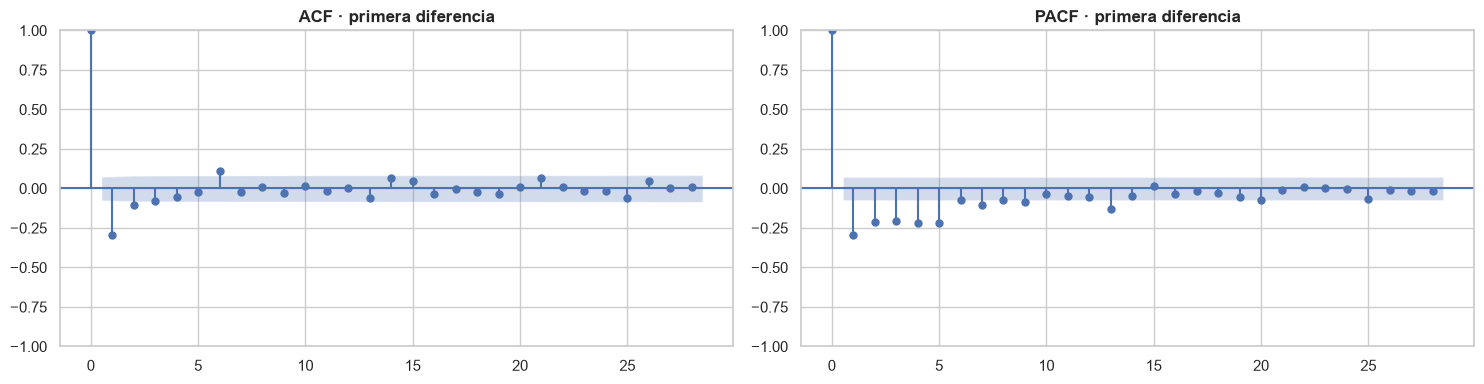

ACF rezagos 1-7:  [-0.3  -0.11 -0.08 -0.06 -0.03  0.11 -0.02]


In [2]:
dy = y.diff().dropna()
fig, ejes = plt.subplots(1, 2, figsize=(15, 4))
plot_acf(dy, lags=28, ax=ejes[0], title="ACF · primera diferencia")
plot_pacf(dy, lags=28, ax=ejes[1], title="PACF · primera diferencia", method="ywm")
plt.tight_layout(); plt.show()
print("ACF rezagos 1-7: ", np.round(acf(dy, nlags=7)[1:], 2))

La ACF de la serie diferenciada tiene un único rezago claramente significativo (el 1, negativo) y luego valores pequeños; la PACF decae de forma gradual. Ese patrón es el de un componente MA(1), con algo de estructura autorregresiva. La propuesta manual es el modelo más simple que lo recoge: **ARIMA(1, 1, 1)**. Como contraste, `pmdarima.auto_arima` busca de forma escalonada el orden que minimiza el AIC con d = 1.

In [3]:
arima_manual = estadisticos.ajustar(y, estadisticos.ORDEN_ARIMA)
orden_auto = tuple(r_est["orden_auto_arima"])
arima_auto = estadisticos.ajustar(y, orden_auto)
diag = pd.DataFrame({f"ARIMA{estadisticos.ORDEN_ARIMA} manual": estadisticos.diagnostico(arima_manual),
                     f"ARIMA{orden_auto} auto_arima": estadisticos.diagnostico(arima_auto)}).T
diag

,AIC,BIC,LjungBox_p_7,LjungBox_p_14
"ARIMA(1, 1, 1) manual","11,537.56","11,551.22",0.06,0.17
"ARIMA(2, 1, 2) auto_arima","11,533.74","11,556.49",0.27,0.41


`auto_arima` elige un modelo más grande con un AIC algo menor, pero el BIC, que penaliza más los parámetros, prefiere el ARIMA(1, 1, 1). La diferencia entre ambos es pequeña.

### 1.2 Residuos del ARIMA(1, 1, 1)

Un modelo bien especificado deja residuos sin autocorrelación (ruido blanco). La prueba de Ljung-Box contrasta esa hipótesis nula: un p-valor bajo indica que queda estructura sin modelar.

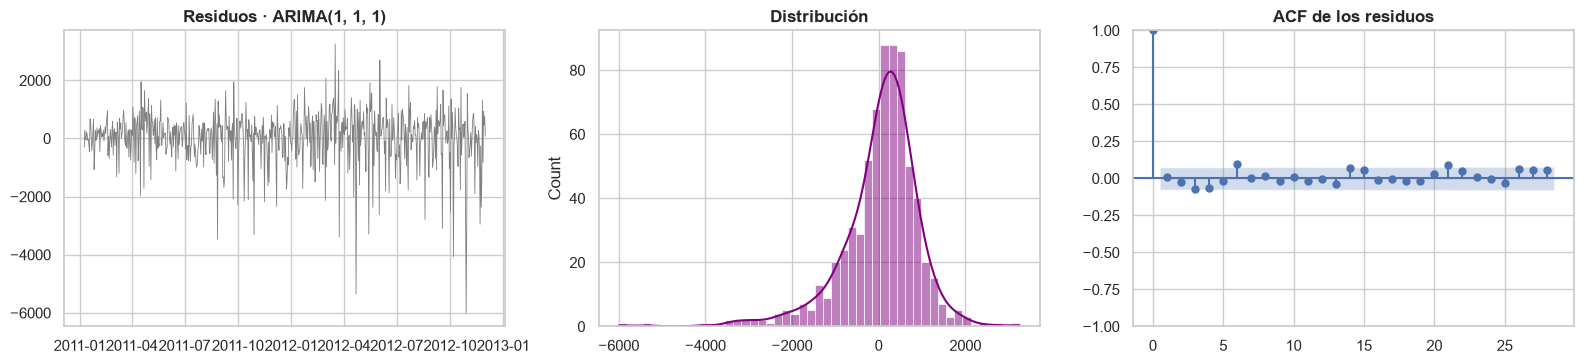

In [4]:
def residuos(res, titulo):
    r = res.resid.iloc[8:]
    fig, ejes = plt.subplots(1, 3, figsize=(16, 3.8))
    ejes[0].plot(r, lw=0.6, color="gray"); ejes[0].set_title(f"Residuos · {titulo}")
    sns.histplot(r, kde=True, ax=ejes[1], color="purple"); ejes[1].set_title("Distribución")
    plot_acf(r, lags=28, ax=ejes[2], title="ACF de los residuos")
    plt.tight_layout(); plt.show()

residuos(arima_manual, "ARIMA(1, 1, 1)")

El p-valor de Ljung-Box del ARIMA(1, 1, 1) en el rezago 7 (0,06) queda justo por encima del umbral del 5 %, y la ACF de los residuos tiene sus mayores valores en torno al rezago 7: queda una estructura semanal sin modelar. Además, los residuos tienen colas pesadas por los días de clima extremo (Sandy, nevadas, lluvias), que ningún modelo univariado puede anticipar.

## 2. SARIMA

### 2.1 Elección de (P, D, Q, s)

El periodo estacional es **s = 7**: la serie es diaria y el patrón que se repite es la semana (notebook 01). Se aplica una diferencia estacional (**D = 1**) además de la regular y se observan las autocorrelaciones en los múltiplos de 7.

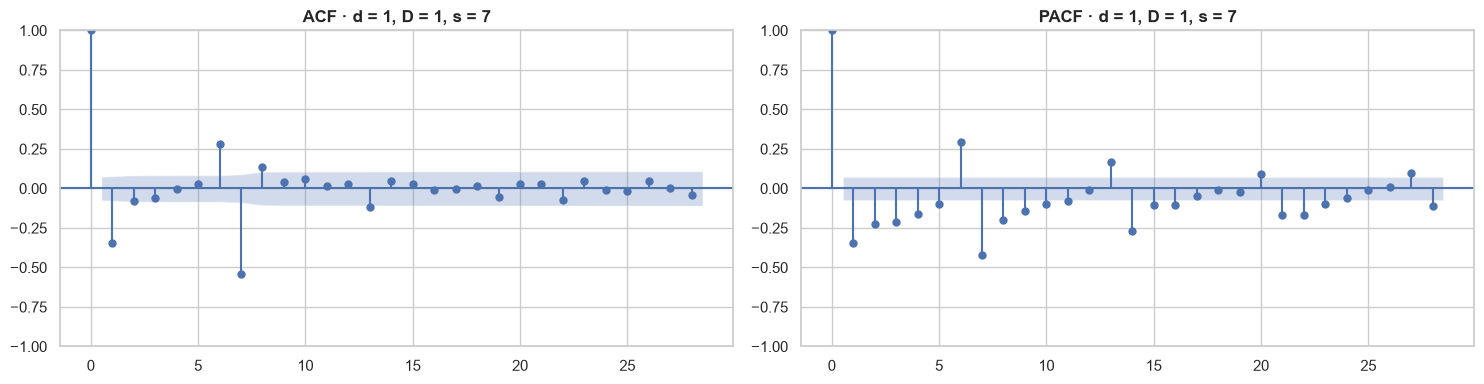

ACF en los rezagos 7, 14 y 21: [-0.54  0.05  0.03]


In [5]:
dsy = y.diff().diff(7).dropna()
fig, ejes = plt.subplots(1, 2, figsize=(15, 4))
plot_acf(dsy, lags=28, ax=ejes[0], title="ACF · d = 1, D = 1, s = 7")
plot_pacf(dsy, lags=28, ax=ejes[1], title="PACF · d = 1, D = 1, s = 7", method="ywm")
plt.tight_layout(); plt.show()
a = acf(dsy, nlags=21)
print("ACF en los rezagos 7, 14 y 21:", np.round(a[[7, 14, 21]], 2))

Tras las dos diferencias, la ACF tiene un pico negativo grande en el rezago 7 y nada relevante en los rezagos 14 y 21, mientras la PACF decae en los múltiplos de 7. Es la firma de un **MA estacional de orden 1** (Q = 1) sin componente AR estacional (P = 0). Para no depender solo de la lectura visual, se ajustan todas las combinaciones con p, q ∈ {0, 1, 2} y P, Q ∈ {0, 1} y se ordenan por AIC.

In [6]:
import itertools
filas = []
for p, q, P, Q in itertools.product(range(3), range(3), range(2), range(2)):
    res = estadisticos.ajustar(y, (p, 1, q), (P, 1, Q, 7))
    filas.append({"modelo": f"({p},1,{q})({P},1,{Q})7", **estadisticos.diagnostico(res)})
rejilla = pd.DataFrame(filas).set_index("modelo").sort_values("AIC")
print("Mejor por BIC:", rejilla["BIC"].idxmin())
rejilla.head(8)

Mejor por BIC: (2,1,1)(0,1,1)7


,AIC,BIC,LjungBox_p_7,LjungBox_p_14
modelo,,,,
"(2,1,1)(0,1,1)7","11,438.20","11,460.90",0.17,0.46
"(1,1,2)(1,1,1)7","11,438.37","11,465.62",0.31,0.65
"(1,1,2)(0,1,1)7","11,438.46","11,461.16",0.16,0.44
"(0,1,2)(1,1,1)7","11,439.62","11,462.33",0.11,0.38
"(2,1,2)(1,1,1)7","11,440.08","11,471.86",0.20,0.49
"(2,1,2)(0,1,1)7","11,441.15","11,468.39",0.14,0.40
"(1,1,1)(0,1,1)7","11,446.36","11,464.52",0.13,0.36
"(1,1,1)(1,1,1)7","11,448.32","11,471.02",0.13,0.36


El mejor modelo por AIC y por BIC es el **SARIMA(2, 1, 1)(0, 1, 1)₇**, coherente con la lectura de la ACF (Q = 1, P = 0). Las alternativas cercanas tienen AIC y BIC muy parecidos, señal de que la elección dentro de este grupo importa poco.

Todos los modelos se ajustan con las restricciones de estacionariedad e invertibilidad por defecto de `statsmodels`. Desactivarlas (`enforce_stationarity=False`) cambia la inicialización del filtro y excluye observaciones de la verosimilitud, así que los AIC resultantes no serían comparables con los de esta tabla.

In [7]:
sarima = estadisticos.ajustar(y, estadisticos.ORDEN_SARIMA, estadisticos.ORDEN_ESTACIONAL)
estadisticos.coeficientes(sarima)

,coef,error_std,p_valor
ar.L1,0.33,0.04,0.00
ar.L2,-0.04,0.04,0.36
ma.L1,-0.90,0.02,0.00
ma.S.L7,-0.95,0.02,0.00
sigma2,"832,599.03","23,346.27",0.00


El AR(1) y el MA(1) regulares son significativos; el AR(2) no lo es, pero el modelo lo conserva porque mejora el AIC y el BIC. El MA estacional es cercano a −1. Eso indica que la estacionalidad semanal es casi **determinista**: la diferencia estacional y un MA estacional cercano a −1 casi se cancelan, y el resultado equivale a un patrón semanal fijo más el resto de la dinámica. Es coherente con la descomposición del notebook 01, donde la componente semanal era pequeña y estable.

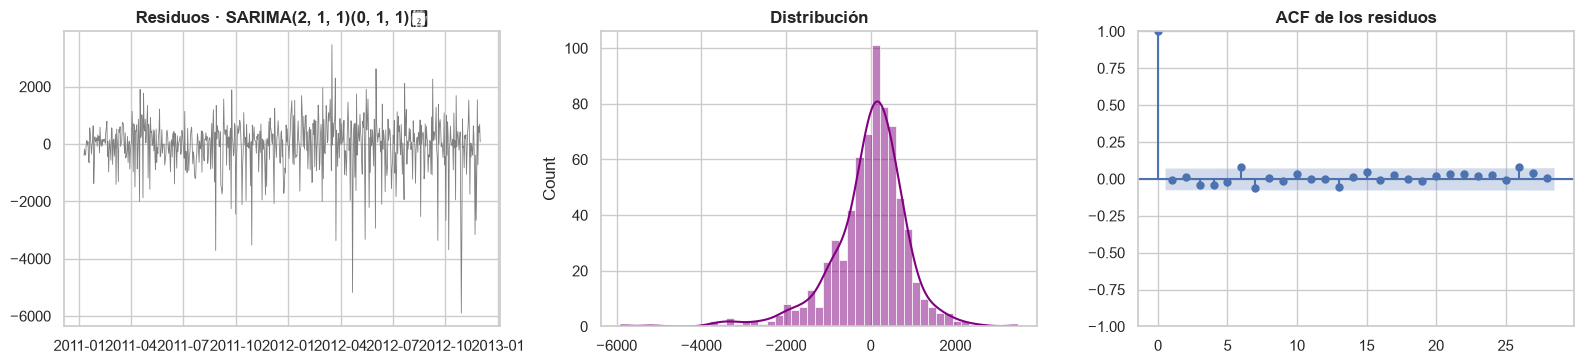

In [8]:
residuos(sarima, "SARIMA(2, 1, 1)(0, 1, 1)₇")

### 2.2 Comparación de criterios de información

In [9]:
criterios = pd.DataFrame({nombre: {k: v for k, v in d.items() if k in ("AIC", "BIC", "LjungBox_p_7", "LjungBox_p_14")}
                          for nombre, d in r_est["diagnostico"].items()}).T
criterios

,AIC,BIC,LjungBox_p_7,LjungBox_p_14
"ARIMA(1, 1, 1)","11,537.56","11,551.22",0.06,0.17
"ARIMA(2, 1, 2) auto","11,533.74","11,556.49",0.27,0.41
SARIMA,"11,438.20","11,460.90",0.17,0.46
SARIMAX completo,"11,100.20","11,150.15",0.27,0.33
SARIMAX solo clima,"11,103.01","11,148.42",0.30,0.36
SARIMAX solo calendario,"11,452.67","11,493.54",0.20,0.55


SARIMA reduce el AIC en unos 95 puntos respecto a los ARIMA y sus residuos pasan la prueba de Ljung-Box en los rezagos 7 y 14: modelar la semana elimina la autocorrelación que quedaba. Los SARIMAX con clima bajan el AIC más de 330 puntos adicionales, la mayor mejora de toda la tabla. El SARIMAX solo con calendario, en cambio, no mejora al SARIMA.

## 3. Predicciones con intervalos

Las bandas son intervalos de predicción del 95 %. En el escenario C el intervalo se ensancha con el horizonte; en el B se mantiene estrecho porque cada día se pronostica con la información del anterior.

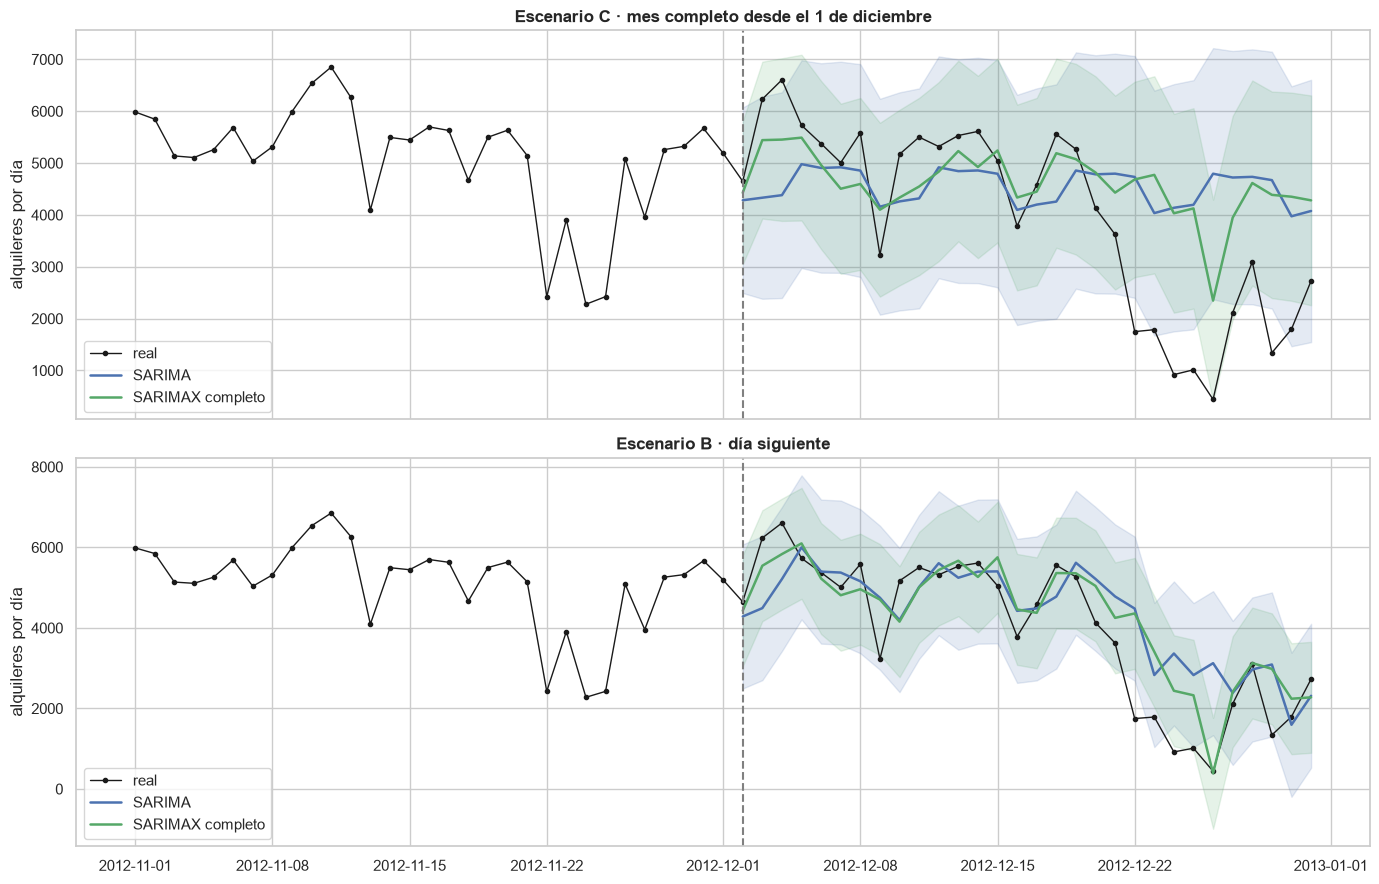

In [10]:
intervalos = {esc: pd.read_csv(RESULTADOS / f"intervalos_{esc}_estadisticos.csv", header=[0, 1], index_col=0, parse_dates=True)
              for esc in ("b", "c")}
fig, ejes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)
for ax, esc, titulo in zip(ejes, ("c", "b"), ("Escenario C · mes completo desde el 1 de diciembre", "Escenario B · día siguiente")):
    ax.plot(day.loc["2012-11-01":, "cnt"], "k.-", lw=1, label="real")
    for modelo, color in (("SARIMA", "C0"), ("SARIMAX completo", "C2")):
        p = intervalos[esc][modelo]
        ax.plot(p["media"], color=color, lw=1.8, label=modelo)
        ax.fill_between(p.index, p["inferior"], p["superior"], color=color, alpha=0.15)
    ax.axvline(INICIO_PRUEBA, color="gray", ls="--"); ax.set(title=titulo, ylabel="alquileres por día"); ax.legend(loc="lower left")
plt.tight_layout(); plt.savefig(FIGURAS / "estadisticos_intervalos.png", dpi=120, bbox_inches="tight"); plt.show()

In [11]:
pd.DataFrame({"B · WAPE": {m: r_b[m]["WAPE"] for m in r_est["diagnostico"]},
              "C · WAPE": {m: r_c[m]["WAPE"] for m in r_est["diagnostico"]},
              "B · MAE": {m: r_b[m]["MAE"] for m in r_est["diagnostico"]},
              "C · MAE": {m: r_c[m]["MAE"] for m in r_est["diagnostico"]}})

,B · WAPE,C · WAPE,B · MAE,C · MAE
"ARIMA(1, 1, 1)",22.13,39.06,874.42,"1,543.33"
"ARIMA(2, 1, 2) auto",24.23,38.45,957.23,"1,518.91"
SARIMA,22.20,36.25,876.94,"1,432.26"
SARIMAX completo,16.88,30.32,667.01,"1,197.87"
SARIMAX solo clima,17.18,30.53,678.58,"1,206.25"
SARIMAX solo calendario,20.34,30.45,803.74,"1,203.07"


Sin exógenas, los modelos solo pueden prolongar el nivel reciente y el patrón semanal: en el escenario C la predicción es casi plana y no anticipa ni los días de lluvia ni la caída de Navidad. Las exógenas de clima son las que permiten seguir las oscilaciones de la demanda dentro del mes.

## 4. SARIMAX

### 4.1 Selección y preparación de las exógenas

Se parte de las variables con mayor correlación con la demanda en el notebook 01 y se revisa la multicolinealidad:

- **Clima:** temperatura (`temp_c`), humedad (`hum_pct`), viento (`viento_kmh`) e indicadoras de la situación del tiempo (`weather_2` = nublado o neblina, `weather_3` = lluvia o nieve ligera; la base es despejado). `weathersit` es categórica: usarla como número supondría que el efecto de pasar de 1 a 2 es igual al de pasar de 2 a 3. `atemp_c` se descarta por su correlación de 0,99 con `temp_c`.
- **Calendario:** festivo (`holiday`) e indicadoras de estación.

In [12]:
clima = variables.exogenas_diarias(entrenamiento, "clima")
vif = pd.Series([variance_inflation_factor(np.column_stack([np.ones(len(clima)), clima.to_numpy()]), i + 1)
                 for i in range(clima.shape[1])], index=clima.columns, name="VIF")
con_atemp = clima.assign(atemp_c=entrenamiento["atemp_c"])
vif_atemp = pd.Series([variance_inflation_factor(np.column_stack([np.ones(len(con_atemp)), con_atemp.to_numpy()]), i + 1)
                       for i in range(con_atemp.shape[1])], index=con_atemp.columns, name="VIF con atemp_c")
pd.concat([vif, vif_atemp], axis=1)

,VIF,VIF con atemp_c
temp_c,1.09,61.29
hum_pct,1.92,1.94
viento_kmh,1.15,1.17
weather_2,1.60,1.61
weather_3,1.37,1.37
atemp_c,NaN,62.09


Con `temp_c` sola, todos los factores de inflación de la varianza (VIF) son bajos; al agregar `atemp_c`, los de las dos temperaturas se disparan, la señal clásica de multicolinealidad.

**Por qué no entra `workingday`.** SARIMAX trabaja sobre la serie diferenciada (d = 1, D = 1, s = 7), y las exógenas entran con las mismas diferencias. Un día laboral es todo día que no es fin de semana ni festivo; al restar el valor de hace 7 días, el fin de semana se cancela y la diferencia estacional de `workingday` queda igual a menos la de `holiday`:

In [13]:
dif = lambda s: s.diff().diff(7).dropna()
print("Correlación entre Δ₇ workingday y Δ₇ holiday:",
      round(np.corrcoef(dif(entrenamiento["workingday"]), dif(entrenamiento["holiday"]))[0, 1], 4))

Correlación entre Δ₇ workingday y Δ₇ holiday: -1.0


Con las dos en el modelo, sus coeficientes no se pueden estimar por separado: salen de magnitud parecida y signo opuesto, con p-valores cercanos a 1. Se conserva solo `holiday`; el efecto del fin de semana ya lo recoge la parte estacional.

### 4.2 Coeficientes y significancia

In [14]:
def exog(conjunto, df=entrenamiento):
    return variables.exogenas_diarias(df, conjunto)

sarimax = estadisticos.ajustar(y, estadisticos.ORDEN_SARIMA, estadisticos.ORDEN_ESTACIONAL, exog("completo"))
coef = estadisticos.coeficientes(sarimax)
coef["significativo (5 %)"] = coef["p_valor"] < 0.05
coef

,coef,error_std,p_valor,significativo (5 %)
temp_c,101.69,8.97,0.00,True
hum_pct,-23.17,2.98,0.00,True
viento_kmh,-39.54,5.21,0.00,True
weather_2,-298.05,74.88,0.00,True
weather_3,"-1,524.93",139.09,0.00,True
holiday,-209.33,115.26,0.07,False
ar.L1,0.35,0.04,0.00,True
ar.L2,0.04,0.04,0.38,False
ma.L1,-0.90,0.03,0.00,True
ma.S.L7,-1.00,0.42,0.02,True


Interpretación de los coeficientes de clima, manteniendo lo demás constante:

- cada grado de temperatura adicional se asocia a unos 100 alquileres más por día;
- cada punto de humedad, a unos 23 menos, y cada km/h de viento, a unos 39 menos;
- un día nublado resta unos 300 alquileres frente a uno despejado, y uno de lluvia o nieve, unos 1.500.

Todos son significativos al 5 %. El festivo resta unos 200 alquileres, pero no es significativo al 5 % (p ≈ 0,07): con solo 20 festivos en el entrenamiento, su efecto queda poco determinado. El MA estacional llega a −1, el límite de invertibilidad: una vez que el clima explica la variación diaria, la semana se comporta como un patrón fijo.

### 4.3 Residuos: SARIMA frente a SARIMAX

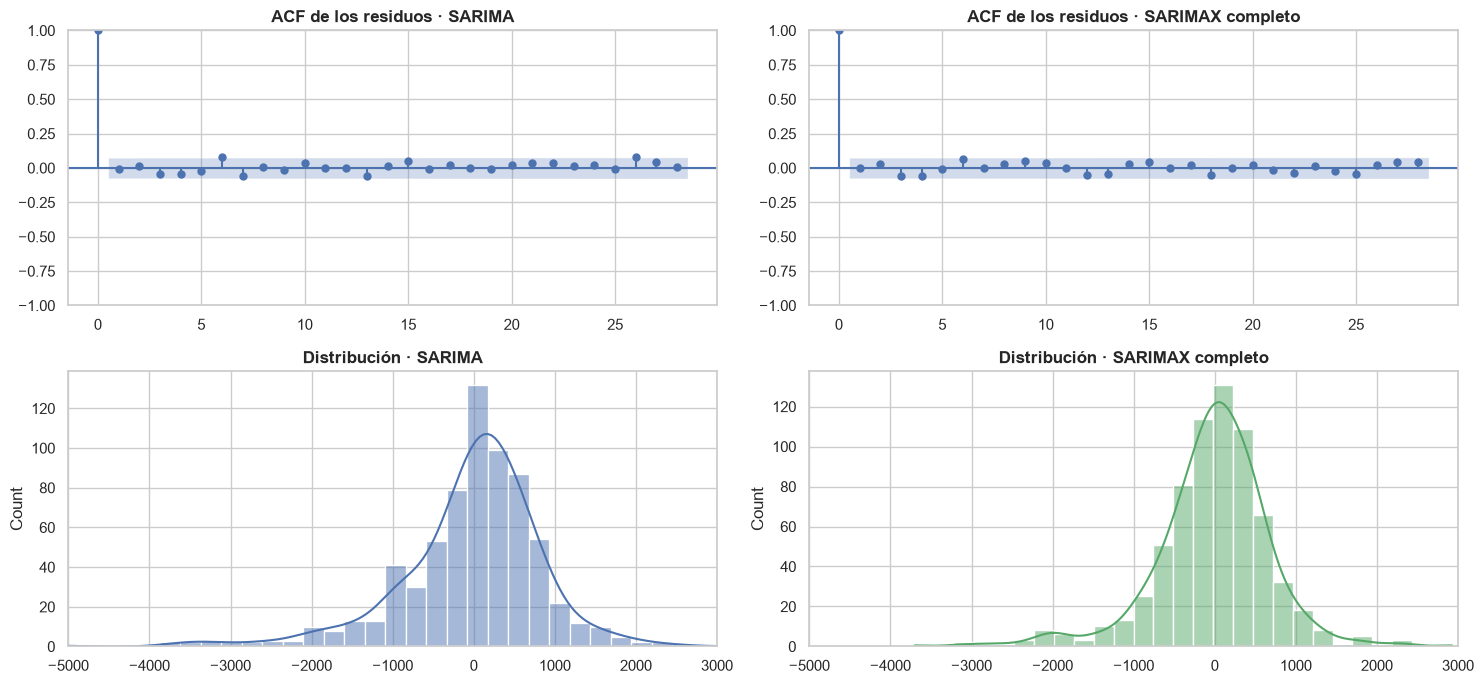

,desv. residuos,AIC,BIC,LjungBox_p_7,LjungBox_p_14
SARIMA,914.42,"11,438.20","11,460.90",0.17,0.46
SARIMAX completo,710.30,"11,100.20","11,150.15",0.27,0.33


In [15]:
fig, ejes = plt.subplots(2, 2, figsize=(15, 7))
for j, (res, nombre) in enumerate([(sarima, "SARIMA"), (sarimax, "SARIMAX completo")]):
    r = res.resid.iloc[8:]
    plot_acf(r, lags=28, ax=ejes[0, j], title=f"ACF de los residuos · {nombre}")
    sns.histplot(r, kde=True, ax=ejes[1, j], color="C0" if j == 0 else "C2", binwidth=250)
    ejes[1, j].set(title=f"Distribución · {nombre}", xlim=(-5000, 3000))
plt.tight_layout(); plt.show()
pd.DataFrame({"SARIMA": {"desv. residuos": sarima.resid.iloc[8:].std(), **estadisticos.diagnostico(sarima)},
              "SARIMAX completo": {"desv. residuos": sarimax.resid.iloc[8:].std(), **estadisticos.diagnostico(sarimax)}}).T

Los dos modelos dejan residuos sin autocorrelación significativa, pero los del SARIMAX son bastante más pequeños: el clima explica una parte grande de la variación diaria que el SARIMA trataba como ruido. La cola izquierda (días con mucha menos demanda de la esperada) se reduce, aunque no desaparece: el cierre por Sandy, por ejemplo, no se explica solo con el clima registrado.

## 5. Clima frente a calendario

In [16]:
modelos_x = ["SARIMA", "SARIMAX completo", "SARIMAX solo clima", "SARIMAX solo calendario"]
pd.DataFrame({"AIC": {m: r_est["diagnostico"][m]["AIC"] for m in modelos_x},
              "BIC": {m: r_est["diagnostico"][m]["BIC"] for m in modelos_x},
              "B · WAPE": {m: r_b[m]["WAPE"] for m in modelos_x},
              "C · WAPE": {m: r_c[m]["WAPE"] for m in modelos_x}})

,AIC,BIC,B · WAPE,C · WAPE
SARIMA,"11,438.20","11,460.90",22.20,36.25
SARIMAX completo,"11,100.20","11,150.15",16.88,30.32
SARIMAX solo clima,"11,103.01","11,148.42",17.18,30.53
SARIMAX solo calendario,"11,452.67","11,493.54",20.34,30.45


In [17]:
estadisticos.coeficientes(estadisticos.ajustar(y, estadisticos.ORDEN_SARIMA, estadisticos.ORDEN_ESTACIONAL, exog("calendario")))

,coef,error_std,p_valor
holiday,173.35,171.80,0.31
season_2,172.96,376.22,0.65
season_3,"1,150.47",434.62,0.01
season_4,664.62,477.36,0.16
ar.L1,0.34,0.04,0.00
ar.L2,-0.04,0.04,0.34
ma.L1,-0.89,0.03,0.00
ma.S.L7,-0.95,0.02,0.00
sigma2,"839,475.34","23,859.74",0.00


En el ajuste, el clima aporta casi toda la mejora: el SARIMAX solo con clima queda prácticamente igual que el completo en AIC, mientras que el de calendario tiene un AIC peor que el del SARIMA (solo la indicadora de verano es significativa). La razón es estructural: la semana ya está en la parte estacional, los festivos son pocos y la estación cambia solo cuatro veces al año, así que tras las diferencias casi no queda variación de calendario que explicar. El clima, en cambio, cambia de un día a otro y mueve la demanda en cientos o miles de alquileres.

En la prueba la lectura depende del escenario:

- **B (día siguiente):** el clima marca la diferencia: 16,9–17,2 % de WAPE con clima frente a 20,3 % solo con calendario y 22,2 % del SARIMA.
- **C (mes completo):** los tres SARIMAX quedan empatados en torno al 30 %. El de calendario no acierta por entender mejor la demanda: el paso de otoño a invierno, el 21 de diciembre, baja su nivel justo cuando empiezan las fiestas. Con 30 días de prueba, esa coincidencia pesa tanto como el clima.


## Resumen

- **ARIMA(1, 1, 1)** propuesto por ACF/PACF y **ARIMA(2, 1, 2)** de `auto_arima`: ajustes casi equivalentes; dejan autocorrelación semanal en los residuos.
- **SARIMA(2, 1, 1)(0, 1, 1)₇**, elegido por AIC y BIC y respaldado por la ACF: residuos sin autocorrelación.
- **SARIMAX** con clima: la mayor mejora en AIC y en el error a un día; las exógenas de calendario aportan poco una vez modelada la semana.
- Sin exógenas, ni ARIMA ni SARIMA superan a la persistencia (repetir el día anterior) en el escenario B; ver notebook 04.
- La comparación con machine learning, escenario por escenario, está en el notebook 04.